# 02b — Logistic Regression Hyperparameter Tuning

## Objective

This notebook keeps `baseline/02_logistic_regression_baseline.ipynb` unchanged as the fixed reference and tests whether modest Logistic Regression tuning improves chronological and cross-network performance.

**Why we are doing this.** The baseline uses scikit-learn defaults for regularization (`C=1`, L2 penalty) with balanced class weights. Tuning tests whether another regularization strength or weighting policy generalizes better.

**Business relevance.** Hyperparameters must be selected without seeing the final time period or CSE-CIC-IDS2018. Otherwise the reported score would no longer estimate performance on future or external-network traffic.


In [1]:
import glob, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

ROOT = '../Data/archive'
RESULTS_DIR = 'results'; os.makedirs(RESULTS_DIR, exist_ok=True)
D17 = f'{ROOT}/CICIDS2017_improved'
SAMPLE18 = '../Data/sample_2018_stratified.csv.gz'
RS = 42
MAX_ITER = 400

def signed_log(values):
    return np.sign(values) * np.log1p(np.abs(values))

def make_logistic(C=1.0, class_weight='balanced'):
    return make_pipeline(
        FunctionTransformer(signed_log),
        StandardScaler(),
        LogisticRegression(
            C=C, penalty='l2', solver='lbfgs', max_iter=MAX_ITER,
            class_weight=class_weight, random_state=RS,
        ),
    )

def metric_row(y_true, y_pred, labels):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    return {
        'macro_precision': precision.mean(),
        'macro_recall': recall.mean(),
        'macro_f1': f1.mean(),
        'weighted_f1': np.average(f1, weights=support),
    }


/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-cheve9f9 because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


## 1. Load and prepare CICIDS2017

**Why we are doing this.** The tuning experiment must use exactly the same target definition, leakage exclusions, finite-value treatment, constant-feature removal, and duplicate policy as the baseline.

**Business relevance.** A fair baseline-versus-tuned comparison changes only the Logistic Regression hyperparameters, not the data population or preprocessing.


In [2]:
files = sorted(glob.glob(f'{D17}/*.csv'))
if not files:
    raise FileNotFoundError(f'No CSV files found under {D17}')

df = pd.concat([pd.read_csv(file_name) for file_name in files], ignore_index=True)
df['y'] = df['Label'].where(~df['Label'].str.endswith(' - Attempted'), 'BENIGN')
df['attempted'] = df['Label'].str.endswith(' - Attempted')
df['ts'] = pd.to_datetime(df['Timestamp'])

drop = ['id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port',
        'Timestamp', 'Attempted Category', 'Label']
X = df.drop(columns=drop + ['y', 'attempted', 'ts']).replace([np.inf, -np.inf], np.nan)
FILL_MAX = X.max()
X = X.fillna(FILL_MAX)
constant = [column for column in X if X[column].nunique() <= 1]
X = X.drop(columns=constant)
FEATURES = list(X.columns)

data = X.assign(y=df.y.values, attempted=df.attempted.values, ts=df.ts.values)
before = len(data)
data = data.drop_duplicates(subset=FEATURES + ['y']).reset_index(drop=True)
LABELS = sorted(data.y.unique(), key=lambda label: (label != 'BENIGN', label))
encoder = LabelEncoder().fit(LABELS)
yall = encoder.transform(data.y)
Xall = data[FEATURES].astype('float32').to_numpy()

print(f'Files: {len(files)} | features: {len(FEATURES)} | rows retained: {len(data):,}')
print(f'Duplicates removed: {before-len(data):,} | constants removed: {constant}')
display(data.y.value_counts().rename('flows').to_frame())
del X, df


Files: 5 | features: 83 | rows retained: 1,841,347
Duplicates removed: 258,629 | constants removed: []


,flows
y,
BENIGN,1434950
DoS Hulk,158468
DDoS,95144
Portscan,90620
Infiltration - Portscan,41179
DoS GoldenEye,7567
FTP-Patator,3972
DoS Slowloris,3859
SSH-Patator,2961


### Section 1 takeaway

The experiment uses the same cleaned CICIDS2017 population and feature set as the baseline, so any performance change can be attributed to tuning rather than a changed preprocessing policy.


## 2. Leakage-safe train, validation, and test periods

**Why we are doing this.** Within each class, the earliest 70% is used for candidate fitting, the next 10% for hyperparameter selection, and the latest 20% is kept untouched for final evaluation.

**Business relevance.** Selecting parameters on the final period would overstate expected future performance. CSE-CIC-IDS2018 remains completely outside parameter selection.


In [3]:
rank = data.groupby('y')['ts'].rank(method='first', pct=True)
train70 = data.index[rank <= 0.70].to_numpy()
validation10 = data.index[(rank > 0.70) & (rank <= 0.80)].to_numpy()
train80 = data.index[rank <= 0.80].to_numpy()
test20 = data.index[rank > 0.80].to_numpy()

def capped_indices(indices, cap_per_class=50_000):
    rng = np.random.default_rng(RS)
    selected = []
    labels = data.y.iloc[indices].values
    for label in LABELS:
        group = indices[labels == label]
        selected.append(rng.choice(group, min(cap_per_class, len(group)), replace=False))
    return np.concatenate(selected)

tune_train = capped_indices(train70)
split_sizes = pd.DataFrame({
    'rows': [len(train70), len(tune_train), len(validation10), len(train80), len(test20)]
}, index=['early 70%', 'class-capped tuning fit', 'middle 10% validation',
          'full first 80% refit', 'latest 20% final test'])
display(split_sizes)
display(pd.crosstab(data.y.iloc[tune_train], columns='tuning rows'))


,rows
early 70%,1288937
class-capped tuning fit,243511
middle 10% validation,184134
full first 80% refit,1473071
latest 20% final test,368276


col_0,tuning rows
y,
BENIGN,50000
Botnet,515
DDoS,50000
DoS GoldenEye,5296
DoS Hulk,50000
DoS Slowhttptest,1218
DoS Slowloris,2701
FTP-Patator,2780
Heartbleed,7


### Section 2 takeaway

Candidate search uses a class-capped subset of the early period for computational efficiency while retaining every rare-class example. Only the winning configuration is refitted on the complete first 80% before the final test.


## 3. Multiclass hyperparameter search

**Why we are doing this.** The search varies L2 regularization strength (`C`) and compares balanced with unweighted fitting. L2 is retained because it is stable under the substantial multicollinearity found during EDA.

**Business relevance.** Validation macro F1 gives every attack class equal influence on selection, preventing benign traffic or the largest attacks from determining the winner.


In [4]:
candidates = [
    {'candidate': 'L2 C=0.03 balanced', 'C': 0.03, 'class_weight': 'balanced'},
    {'candidate': 'L2 C=0.10 balanced', 'C': 0.10, 'class_weight': 'balanced'},
    {'candidate': 'L2 C=0.30 balanced', 'C': 0.30, 'class_weight': 'balanced'},
    {'candidate': 'L2 C=1.00 balanced (baseline settings)', 'C': 1.00, 'class_weight': 'balanced'},
    {'candidate': 'L2 C=3.00 balanced', 'C': 3.00, 'class_weight': 'balanced'},
    {'candidate': 'L2 C=1.00 unweighted', 'C': 1.00, 'class_weight': None},
]

search_rows = []
encoded_labels = encoder.transform(LABELS)
for candidate in candidates:
    model = make_logistic(candidate['C'], candidate['class_weight'])
    started = time.perf_counter()
    model.fit(Xall[tune_train], yall[tune_train])
    fit_seconds = time.perf_counter() - started
    predicted = model.predict(Xall[validation10])
    metrics = metric_row(yall[validation10], predicted, encoded_labels)
    lr = model.named_steps['logisticregression']
    search_rows.append({
        **candidate, **metrics, 'fit_seconds': fit_seconds,
        'max_iterations_used': int(lr.n_iter_.max()),
        'converged': bool(lr.n_iter_.max() < MAX_ITER),
    })
    print(f"{candidate['candidate']:<42} validation macro F1 {metrics['macro_f1']:.4f} | {fit_seconds:.1f}s")

search = pd.DataFrame(search_rows).sort_values(
    ['macro_f1', 'macro_recall'], ascending=False
).reset_index(drop=True)
search.to_csv(f'{RESULTS_DIR}/02_logistic_tuning_search.csv', index=False)
best = search.iloc[0]
display(search.round(4))
print(f"Selected: {best['candidate']} using validation macro F1 only")


L2 C=0.03 balanced                         validation macro F1 0.6290 | 26.1s


L2 C=0.10 balanced                         validation macro F1 0.7034 | 25.5s


L2 C=0.30 balanced                         validation macro F1 0.6899 | 20.0s


L2 C=1.00 balanced (baseline settings)     validation macro F1 0.7211 | 21.0s


L2 C=3.00 balanced                         validation macro F1 0.7353 | 15.1s


L2 C=1.00 unweighted                       validation macro F1 0.7409 | 15.6s


,candidate,C,class_weight,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,max_iterations_used,converged
0,L2 C=1.00 unweighted,1.00,None,0.7085,0.7981,0.7409,0.9870,15.6496,230,True
1,L2 C=3.00 balanced,3.00,balanced,0.6910,0.9261,0.7353,0.9858,15.1135,225,True
2,L2 C=1.00 balanced (baseline settings),1.00,balanced,0.6759,0.9261,0.7211,0.9855,20.9529,286,True
3,L2 C=0.10 balanced,0.10,balanced,0.6575,0.9869,0.7034,0.9811,25.4728,388,True
4,L2 C=0.30 balanced,0.30,balanced,0.6376,0.9880,0.6899,0.9837,19.9764,305,True
5,L2 C=0.03 balanced,0.03,balanced,0.5721,0.9860,0.6290,0.9763,26.0558,400,False


Selected: L2 C=1.00 unweighted using validation macro F1 only


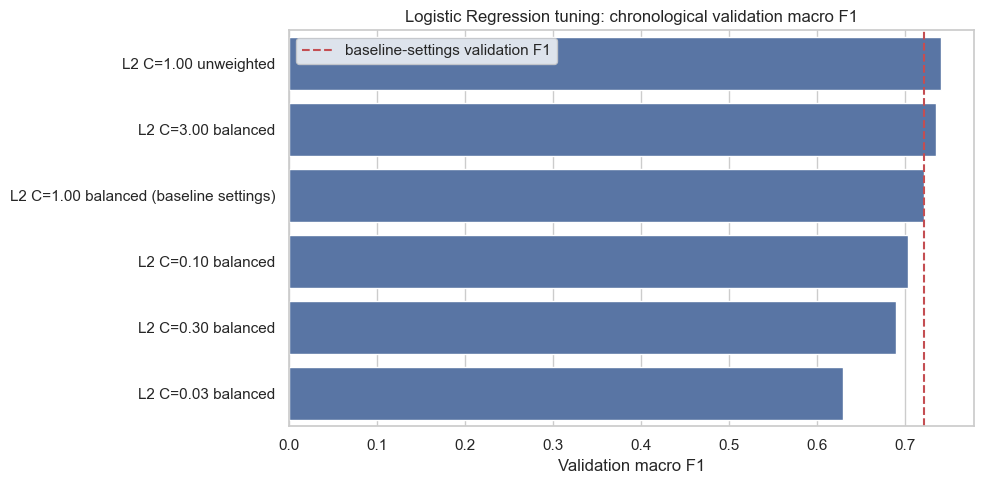

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=search, y='candidate', x='macro_f1', color='#4C72B0', ax=ax)
ax.axvline(search.loc[search.candidate.str.contains('baseline settings'), 'macro_f1'].iloc[0],
           color='#C44E52', linestyle='--', label='baseline-settings validation F1')
ax.set_title('Logistic Regression tuning: chronological validation macro F1')
ax.set_xlabel('Validation macro F1'); ax.set_ylabel('')
ax.legend(); plt.tight_layout(); plt.show()


### Section 3 takeaway

The selected configuration is determined exclusively by middle-period macro F1. The search table also records convergence and fit time so a marginal score change can be weighed against operational cost.


## 4. Refit the winner and evaluate the held-out data

**Why we are doing this.** After selection, the winner is refitted once on all observations in the first 80% of each class and evaluated once on the latest 20%. For presentation consistency with the baseline notebook, the same fixed winner is then refitted and evaluated on the baseline's reproducible stratified random split.

**Business relevance.** The chronological result remains the primary comparison because it tests whether tuning improves future-period detection. The random-split macro F1 is a secondary, like-for-like benchmark only; it does not participate in hyperparameter selection.

In [6]:
best_model = make_logistic(float(best.C), best.class_weight)
started = time.perf_counter()
best_model.fit(Xall[train80], yall[train80])
chrono_fit_seconds = time.perf_counter() - started
test_pred = best_model.predict(Xall[test20])

precision, recall, f1, support = precision_recall_fscore_support(
    yall[test20], test_pred, labels=encoded_labels, zero_division=0
)
chrono_per_class = pd.DataFrame({
    'split': 'time-ordered', 'model': 'Logistic Regression tuned',
    'class': LABELS, 'precision': precision, 'recall': recall,
    'f1': f1, 'support': support,
})
chrono_summary = {
    'split': 'time-ordered', 'model': 'Logistic Regression tuned',
    **metric_row(yall[test20], test_pred, encoded_labels),
    'attack_macro_f1': chrono_per_class.loc[chrono_per_class['class'] != 'BENIGN', 'f1'].mean(),
    'fit_seconds': chrono_fit_seconds, 'selected_C': float(best.C),
    'selected_class_weight': str(best.class_weight),
}

# Secondary presentation benchmark: reuse the baseline notebook's exact random split.
random_train, random_test = train_test_split(
    data.index.to_numpy(), test_size=0.2, stratify=data.y, random_state=RS
)
random_model = make_logistic(float(best.C), best.class_weight)
started = time.perf_counter()
random_model.fit(Xall[random_train], yall[random_train])
random_fit_seconds = time.perf_counter() - started
random_pred = random_model.predict(Xall[random_test])

precision, recall, f1, support = precision_recall_fscore_support(
    yall[random_test], random_pred, labels=encoded_labels, zero_division=0
)
random_per_class = pd.DataFrame({
    'split': 'random', 'model': 'Logistic Regression tuned',
    'class': LABELS, 'precision': precision, 'recall': recall,
    'f1': f1, 'support': support,
})
random_summary = {
    'split': 'random', 'model': 'Logistic Regression tuned',
    **metric_row(yall[random_test], random_pred, encoded_labels),
    'attack_macro_f1': random_per_class.loc[random_per_class['class'] != 'BENIGN', 'f1'].mean(),
    'fit_seconds': random_fit_seconds, 'selected_C': float(best.C),
    'selected_class_weight': str(best.class_weight),
}

tuned_per_class = pd.concat([chrono_per_class, random_per_class], ignore_index=True)
tuned_summary = pd.DataFrame([chrono_summary, random_summary])
tuned_per_class.to_csv(f'{RESULTS_DIR}/02_logistic_tuned_per_class.csv', index=False)
tuned_summary.to_csv(f'{RESULTS_DIR}/02_logistic_tuned_summary.csv', index=False)

baseline_summary = pd.read_csv('../baseline/02_logistic_baseline_summary.csv')
baseline_time = baseline_summary[baseline_summary.split.eq('time-ordered')].copy()
comparison = pd.concat([
    baseline_summary.assign(source='untuned baseline'),
    tuned_summary.assign(source='tuned'),
], ignore_index=True, sort=False)
comparison.to_csv(f'{RESULTS_DIR}/02_logistic_baseline_vs_tuned.csv', index=False)
display(comparison[['split', 'source', 'macro_precision', 'macro_recall', 'macro_f1',
                    'weighted_f1', 'attack_macro_f1']].round(4))
display(chrono_per_class.sort_values('f1').round(4))
print(f'Chronological refit time: {chrono_fit_seconds:.1f}s')
print(f'Random-split refit time: {random_fit_seconds:.1f}s')
print('Random-split results are secondary and did not influence model selection.')

,split,source,macro_precision,macro_recall,macro_f1,weighted_f1,attack_macro_f1
0,random,untuned baseline,0.7919,0.9779,0.8241,0.9898,0.8126
1,time-ordered,untuned baseline,0.6868,0.9457,0.7278,0.9841,0.7101
2,time-ordered,tuned,0.7857,0.7760,0.7746,0.9889,0.7598
3,random,tuned,0.8859,0.8151,0.8298,0.9937,0.8184


,split,model,class,precision,recall,f1,support
14,time-ordered,Logistic Regression tuned,Web Attack - SQL Injection,0.0000,0.0000,0.0000,3
15,time-ordered,Logistic Regression tuned,Web Attack - XSS,0.0000,0.0000,0.0000,4
5,time-ordered,Logistic Regression tuned,DoS Slowhttptest,0.4251,0.5460,0.4780,348
6,time-ordered,Logistic Regression tuned,DoS Slowloris,0.9287,0.6075,0.7345,772
8,time-ordered,Logistic Regression tuned,Heartbleed,1.0000,0.6667,0.8000,3
10,time-ordered,Logistic Regression tuned,Infiltration - Portscan,0.8930,0.8198,0.8548,8236
13,time-ordered,Logistic Regression tuned,Web Attack - Brute Force,0.7500,1.0000,0.8571,15
9,time-ordered,Logistic Regression tuned,Infiltration,0.8750,0.8750,0.8750,8
11,time-ordered,Logistic Regression tuned,Portscan,0.8783,0.9738,0.9236,18124
1,time-ordered,Logistic Regression tuned,Botnet,0.8690,0.9865,0.9241,148


Chronological refit time: 53.2s
Random-split refit time: 90.5s
Random-split results are secondary and did not influence model selection.


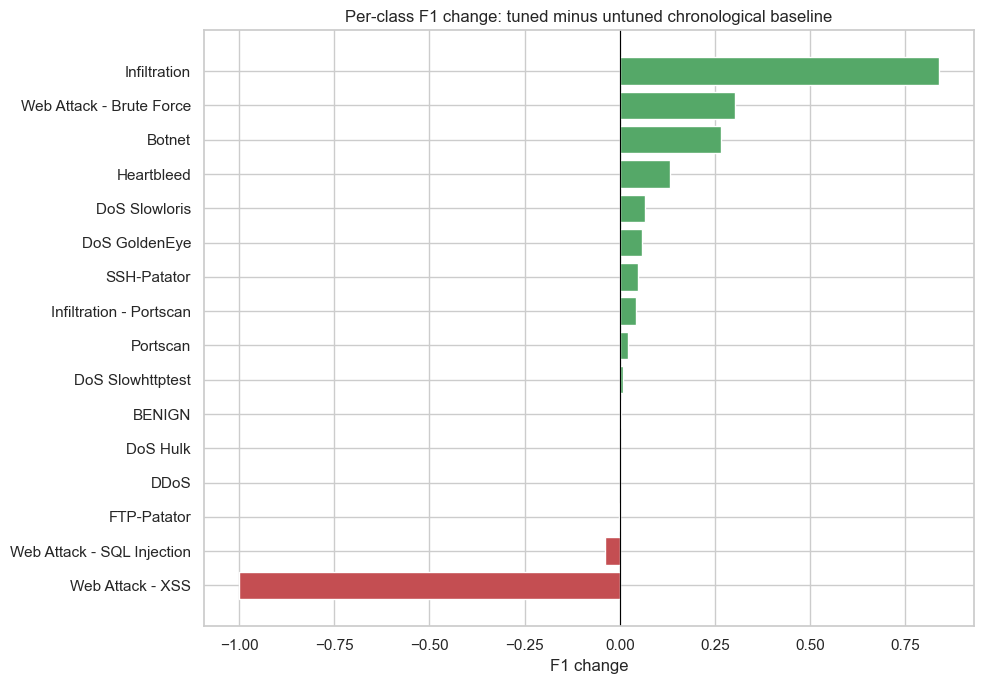

,class,baseline F1,tuned F1,change
15,Web Attack - XSS,1.0000,0.0000,-1.0000
14,Web Attack - SQL Injection,0.0390,0.0000,-0.0390
7,FTP-Patator,0.9956,0.9937,-0.0019
2,DDoS,0.9990,0.9985,-0.0005
4,DoS Hulk,0.9986,0.9993,0.0007
0,BENIGN,0.9937,0.9965,0.0028
5,DoS Slowhttptest,0.4686,0.4780,0.0093
11,Portscan,0.9023,0.9236,0.0213
10,Infiltration - Portscan,0.8111,0.8548,0.0437
12,SSH-Patator,0.9286,0.9772,0.0485


In [7]:
baseline_per_class = pd.read_csv('../baseline/02_logistic_baseline_per_class.csv')
baseline_pc = baseline_per_class[baseline_per_class.split.eq('time-ordered')][['class', 'f1']].rename(columns={'f1': 'baseline F1'})
class_compare = baseline_pc.merge(tuned_per_class[tuned_per_class.split.eq('time-ordered')][['class', 'f1']].rename(columns={'f1': 'tuned F1'}), on='class')
class_compare['change'] = class_compare['tuned F1'] - class_compare['baseline F1']
class_compare = class_compare.sort_values('change')

fig, ax = plt.subplots(figsize=(10, 7))
colors = np.where(class_compare['change'] >= 0, '#55A868', '#C44E52')
ax.barh(class_compare['class'], class_compare['change'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Per-class F1 change: tuned minus untuned chronological baseline')
ax.set_xlabel('F1 change'); ax.set_ylabel('')
plt.tight_layout(); plt.show()
display(class_compare.round(4))


### Section 4 takeaway

The final comparison separates validation improvement from genuine test improvement. Per-class changes are reported because a similar macro F1 can conceal gains for some attacks and regressions for others.


## 5. Binary tuning for the primary attack-detection goal

**Why we are doing this.** The primary business goal is binary—attack versus benign—so its hyperparameters are selected separately using binary validation macro F1 rather than reusing the multiclass winner.

**Business relevance.** Binary selection must balance attack recall against false alarms. A detector that catches attacks but overwhelms analysts with benign alerts is not operationally useful.


In [8]:
binary_y = (data.y.values != 'BENIGN').astype(int)
binary_rows = []
for candidate in candidates:
    model = make_logistic(candidate['C'], candidate['class_weight'])
    started = time.perf_counter()
    model.fit(Xall[tune_train], binary_y[tune_train])
    fit_seconds = time.perf_counter() - started
    predicted = model.predict(Xall[validation10])
    precision, recall, f1, support = precision_recall_fscore_support(
        binary_y[validation10], predicted, labels=[0, 1], zero_division=0
    )
    binary_rows.append({
        **candidate, 'macro_f1': f1.mean(), 'attack_precision': precision[1],
        'attack_recall': recall[1], 'attack_f1': f1[1],
        'false_alarm_rate': 1 - recall[0], 'fit_seconds': fit_seconds,
    })

binary_search = pd.DataFrame(binary_rows).sort_values(
    ['macro_f1', 'attack_recall'], ascending=False
).reset_index(drop=True)
binary_search.to_csv(f'{RESULTS_DIR}/02_logistic_binary_tuning_search.csv', index=False)
binary_best = binary_search.iloc[0]
display(binary_search.round(4))
print(f"Selected binary configuration: {binary_best['candidate']}")

binary_model = make_logistic(float(binary_best.C), binary_best.class_weight)
# Match the original binary baseline's refit population exactly: retain all
# attacks and cap benign training rows at 400,000. This isolates the effect of
# hyperparameters from the effect of changing the class mixture.
benign_train80 = train80[binary_y[train80] == 0]
attack_train80 = train80[binary_y[train80] == 1]
binary_rng = np.random.default_rng(RS)
binary_fit_idx = np.r_[
    binary_rng.choice(benign_train80, min(400_000, len(benign_train80)), replace=False),
    attack_train80,
]
binary_model.fit(Xall[binary_fit_idx], binary_y[binary_fit_idx])
binary_test_pred = binary_model.predict(Xall[test20])
bp, br, bf, bs = precision_recall_fscore_support(
    binary_y[test20], binary_test_pred, labels=[0, 1], zero_division=0
)
binary_test = pd.DataFrame({
    'class': ['BENIGN', 'effective attack'], 'precision': bp, 'recall': br,
    'f1': bf, 'support': bs,
})
display(binary_test.round(4))
print(f'Binary refit rows: {len(binary_fit_idx):,} (matched to baseline policy)')
print(f'Binary test macro F1: {bf.mean():.4f} | attack recall: {br[1]:.4f} | false-alarm rate: {1-br[0]:.4f}')


,candidate,C,class_weight,macro_f1,attack_precision,attack_recall,attack_f1,false_alarm_rate,fit_seconds
0,L2 C=1.00 balanced (baseline settings),1.00,balanced,0.9826,0.9527,0.9944,0.9731,0.0140,4.4035
1,L2 C=0.30 balanced,0.30,balanced,0.9826,0.9524,0.9945,0.9730,0.0141,3.4553
2,L2 C=0.10 balanced,0.10,balanced,0.9822,0.9515,0.9943,0.9724,0.0144,2.6805
3,L2 C=3.00 balanced,3.00,balanced,0.9821,0.9509,0.9947,0.9723,0.0145,5.3534
4,L2 C=0.03 balanced,0.03,balanced,0.9812,0.9489,0.9941,0.9710,0.0152,2.2447
5,L2 C=1.00 unweighted,1.00,None,0.9538,0.8712,0.9961,0.9295,0.0417,4.3506


Selected binary configuration: L2 C=1.00 balanced (baseline settings)


,class,precision,recall,f1,support
0,BENIGN,0.9976,0.9911,0.9943,286990
1,effective attack,0.9692,0.9916,0.9803,81286


Binary refit rows: 725,111 (matched to baseline policy)
Binary test macro F1: 0.9873 | attack recall: 0.9916 | false-alarm rate: 0.0089


## 6. External CSE-CIC-IDS2018 check

**Why we are doing this.** The selected binary configuration is applied to compatible 2018 attack families only after all parameter choices are complete.

**Business relevance.** This is the strongest test of the project’s generalization goal: whether a detector learned on one network retains attack detection and a tolerable benign false-alarm rate in another.


In [9]:
if not os.path.exists(SAMPLE18):
    raise FileNotFoundError('Run ../01_eda_2018_extended.ipynb to create the cached 2018 sample.')
s18 = pd.read_csv(SAMPLE18)
s18['attempted'] = s18.Label.str.endswith(' - Attempted')
s18[FEATURES] = s18[FEATURES].replace([np.inf, -np.inf], np.nan).fillna(FILL_MAX)

MAP18 = {
    'BENIGN': 'BENIGN', 'SSH-BruteForce': 'SSH-Patator', 'DoS Hulk': 'DoS Hulk',
    'DoS GoldenEye': 'DoS GoldenEye', 'DoS Slowloris': 'DoS Slowloris',
    'DDoS-LOIC-HTTP': 'DDoS', 'Botnet Ares': 'Botnet',
    'Infiltration - NMAP Portscan': 'Infiltration - Portscan',
    'Web Attack - Brute Force': 'Web Attack - Brute Force',
    'Web Attack - XSS': 'Web Attack - XSS', 'Web Attack - SQL': 'Web Attack - SQL Injection',
    'Infiltration - Communication Victim Attacker': 'Infiltration',
}
s18['family'] = s18.Label.map(MAP18)
shared = [family for family in MAP18.values()
          if (s18.family == family).sum() >= 30 and (data.y == family).sum() >= 30]

test17 = data.iloc[test20][FEATURES + ['y', 'attempted']].copy()
test17['eval_group'] = np.where(test17.attempted, 'Attempted (scored as benign)', test17.y)
s18['eval_group'] = np.where(s18.attempted, 'Attempted (scored as benign)', s18.family)

def alarm_rates(frame, group_column):
    predicted = binary_model.predict(frame[FEATURES])
    return pd.Series(predicted).groupby(frame[group_column].values).mean()

tuned_cross_year = pd.DataFrame({
    '2017 time-test': alarm_rates(test17, 'eval_group'),
    '2018 sample': alarm_rates(s18.dropna(subset=['eval_group']), 'eval_group'),
}).reindex(['BENIGN', 'Attempted (scored as benign)'] + [f for f in shared if f != 'BENIGN'])
tuned_cross_year.index = [
    'BENIGN false-alarm rate' if value == 'BENIGN' else
    'Attempted alarm rate' if value.startswith('Attempted') else f'{value} detection rate'
    for value in tuned_cross_year.index
]
tuned_cross_year.to_csv(f'{RESULTS_DIR}/02_logistic_tuned_cross_year.csv')

baseline_cross_year = pd.read_csv('../baseline/02_logistic_cross_year_detection.csv', index_col=0)
cross_year_compare = baseline_cross_year.join(
    tuned_cross_year, lsuffix=' baseline', rsuffix=' tuned'
)
display(cross_year_compare.round(4))


,2017 time-test baseline,2018 sample baseline,2017 time-test tuned,2018 sample tuned
BENIGN false-alarm rate,0.0054,0.0326,0.0054,0.0326
Attempted alarm rate,0.8365,0.8890,0.8365,0.8890
SSH-Patator detection rate,0.9798,0.3471,0.9798,0.3471
DoS Hulk detection rate,0.9993,0.0224,0.9993,0.0224
DoS GoldenEye detection rate,0.9604,0.5838,0.9604,0.5838
DoS Slowloris detection rate,0.9832,0.9975,0.9832,0.9975
DDoS detection rate,1.0000,1.0000,1.0000,1.0000
Botnet detection rate,0.0000,0.0001,0.0000,0.0001
Infiltration - Portscan detection rate,0.9805,0.8362,0.9805,0.8362
Web Attack - Brute Force detection rate,0.0000,0.0000,0.0000,0.0000


## 7. Programmatic tuning summary

The table below is generated from the search and test objects. It updates automatically whenever the data, candidates, or selected configuration changes.


In [10]:
baseline_row = baseline_summary[baseline_summary.split.eq('time-ordered')].iloc[0]
tuned_row = tuned_summary[tuned_summary.split.eq('time-ordered')].iloc[0]
baseline_random_row = baseline_summary[baseline_summary.split.eq('random')].iloc[0]
tuned_random_row = tuned_summary[tuned_summary.split.eq('random')].iloc[0]
summary_findings = pd.DataFrame([
    ('Multiclass selection', str(best.candidate),
     f"Validation macro F1 {best.macro_f1:.4f}."),
    ('Chronological multiclass test', 'Latest 20% of each class',
     f"Macro F1 changed from {baseline_row.macro_f1:.4f} to {tuned_row.macro_f1:.4f} "
     f"({tuned_row.macro_f1-baseline_row.macro_f1:+.4f})."),
    ('Random-split presentation check', 'Secondary; excluded from tuning selection',
     f"Macro F1 changed from {baseline_random_row.macro_f1:.4f} to {tuned_random_row.macro_f1:.4f} "
     f"({tuned_random_row.macro_f1-baseline_random_row.macro_f1:+.4f})."),
    ('Attack-class test average', 'Chronological attack macro F1',
     f"Changed from {baseline_row.attack_macro_f1:.4f} to {tuned_row.attack_macro_f1:.4f} "
     f"({tuned_row.attack_macro_f1-baseline_row.attack_macro_f1:+.4f})."),
    ('Binary selection', str(binary_best.candidate),
     f"Validation macro F1 {binary_best.macro_f1:.4f}; validation false-alarm rate {binary_best.false_alarm_rate:.4f}."),
    ('Binary chronological test', 'Latest 20%',
     f"Attack recall {br[1]:.4f}; attack F1 {bf[1]:.4f}; false-alarm rate {1-br[0]:.4f}."),
    ('2018 external check', 'No 2018 tuning',
     f"BENIGN false-alarm rate {tuned_cross_year.loc['BENIGN false-alarm rate', '2018 sample']:.4f}; "
     f"mean shared-family detection rate {tuned_cross_year.loc[tuned_cross_year.index.str.endswith('detection rate'), '2018 sample'].mean():.4f}."),
], columns=['Area', 'Decision or evaluation', 'Result'])
display(summary_findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Area,Decision or evaluation,Result
Multiclass selection,L2 C=1.00 unweighted,Validation macro F1 0.7409.
Chronological multiclass test,Latest 20% of each class,Macro F1 changed from 0.7278 to 0.7746 (+0.0468).
Random-split presentation check,Secondary; excluded from tuning selection,Macro F1 changed from 0.8241 to 0.8298 (+0.0057).
Attack-class test average,Chronological attack macro F1,Changed from 0.7101 to 0.7598 (+0.0497).
Binary selection,L2 C=1.00 balanced (baseline settings),Validation macro F1 0.9826; validation false-alarm rate 0.0140.
Binary chronological test,Latest 20%,Attack recall 0.9916; attack F1 0.9803; false-alarm rate 0.0089.
2018 external check,No 2018 tuning,BENIGN false-alarm rate 0.0326; mean shared-family detection rate 0.4213.


### Final interpretation

Tuning is considered successful only if validation selection produces a meaningful improvement on the untouched chronological test without an unacceptable increase in false alarms or a collapse in 2018 detection. If gains are negligible, the simpler untuned baseline remains the more defensible reference.
